In [2]:
import numpy as np
import corner
import glob
import importlib
import matplotlib.pyplot as plt
import os
from astropy.time import Time

import discovery as ds
import discovery.models.nanograv as ds_nanograv
import discovery.samplers.numpyro as ds_numpyro

importlib.reload(ds)
importlib.reload(ds_nanograv)
importlib.reload(ds_numpyro)
importlib.reload(ds.pulsar)
importlib.reload(ds.likelihood)
importlib.reload(ds.signals)
importlib.reload(ds.matrix)
importlib.reload(ds.prior)

<module 'discovery.prior' from '/h/mit227/discovery-ppa/src/discovery/prior.py'>

In [3]:
PA_path = os.environ.get("PA_WRITE")
print(PA_path)
fitres_path = os.environ.get("FITRES")
print(fitres_path)

/DATA/CARINA_4/mit227/subband_PA_data
/DATA/CARINA_4/mit227/fit_results


In [4]:
book_path = os.environ.get("BOOK")
fitres_path = f"{book_path}/fit_results"
print(fitres_path)

/DATA/CARINA_4/mit227/fit_results


In [5]:
npz_list = glob.glob(f"{fitres_path}/*.npz")
pdf_list = glob.glob(f"{fitres_path}/*.pdf")
print(npz_list)
print(pdf_list)

['/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261027-120408.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261027-120650.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261029-174700.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261029-181506.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261030-200120.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261031-171241.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261031-234318.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261031-235935.npz']
['/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261029-174700.pdf', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261029-181506.pdf', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261030-200120.pdf', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261031-171241.pdf', '/DATA/CARINA_4/mit227/fit

#### Last fit

[[ 0.98945554 -1.95241436 -2.06937557 -1.48583427  1.5632533  -8.22272796]
 [ 0.98332578 -1.88479374 -2.07073014 -1.38440872  1.73528172 -8.37491855]
 [ 0.98229876 -1.86017776 -2.06144285 -1.3805226   1.73496383 -8.28254254]
 ...
 [ 0.98763405 -1.88354449 -2.06260596 -1.42154421  1.56229509 -8.3915882 ]
 [ 0.97243793 -1.83593111 -2.08191214 -1.470733    1.56540585 -8.29324246]
 [ 0.98982018 -2.01271074 -2.05184616 -1.50791264  1.48220258 -8.18720106]]


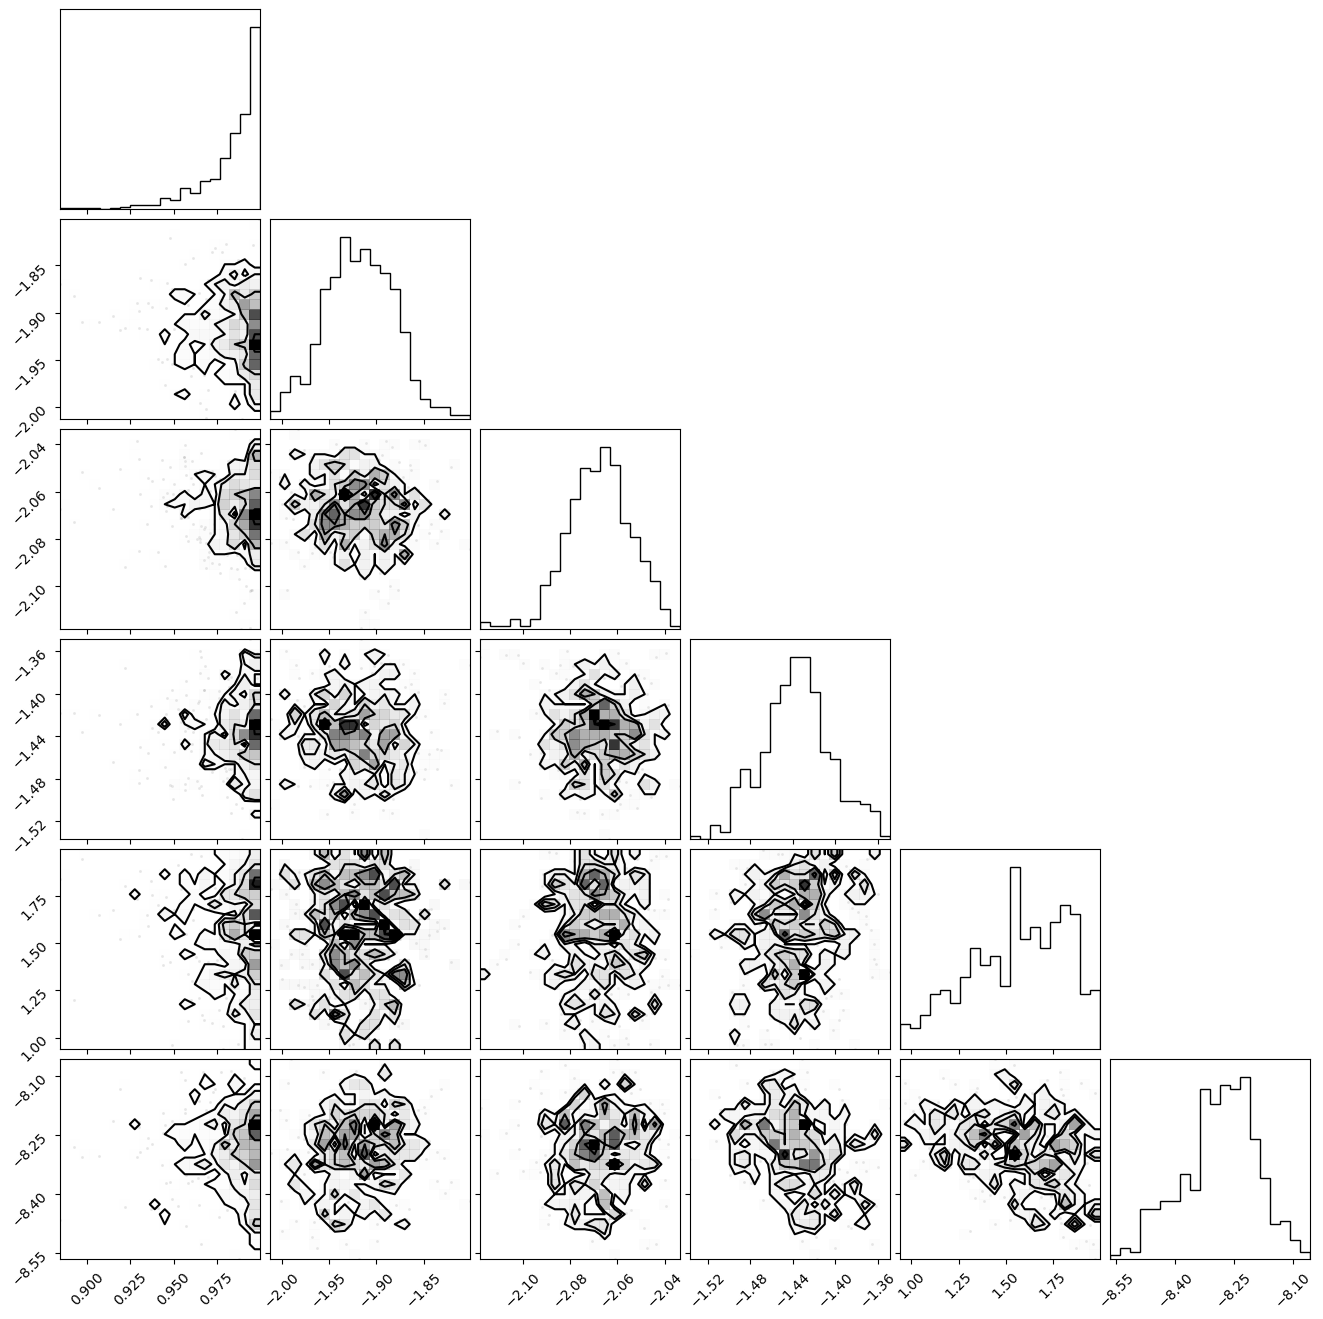

In [6]:
with np.load(npz_list[-1]) as loaded_results:
    print(loaded_results['raw'])
    figure = corner.corner(
        loaded_results['raw'],
    )
    plt.show()

#### 2026/10/29 18:15:06

In [7]:
psr = ds.Pulsar.read_feather(f'{PA_path}/J0835-4510.PA.head_derot.minusSBmean.feather', json_metadata=False)
m_RM = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement(psr, tnequad=True),
                         ds.makegp_ecorr(psr),
                         ds.makegp_erm(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp')
                         ])
logL = m_RM.logL

J0835-4510_P574_UWL_efac       mean=+9.652  std=0.350  range=[7.639, 10.000]
J0835-4510_P574_UWL_log10_ecorr mean=-1.919  std=0.034  range=[-2.017, -1.815]
J0835-4510_P574_UWL_log10_tnequad mean=-3.051  std=0.022  range=[-3.103, -2.938]
J0835-4510_log10_erm           mean=-1.432  std=0.032  range=[-1.509, -1.297]
J0835-4510_rmgp_gamma          mean=+1.534  std=0.263  range=[0.804, 1.988]
J0835-4510_rmgp_log10_A        mean=-8.291  std=0.085  range=[-8.612, -8.018]
{'J0835-4510_P574_UWL_efac': np.float64(9.652271541287284), 'J0835-4510_P574_UWL_log10_ecorr': np.float64(-1.9192543957341908), 'J0835-4510_P574_UWL_log10_tnequad': np.float64(-3.050942138752644), 'J0835-4510_log10_erm': np.float64(-1.4324419308554628), 'J0835-4510_rmgp_gamma': np.float64(1.5340360275610267), 'J0835-4510_rmgp_log10_A': np.float64(-8.291083936375541)}
-6.283294e+03


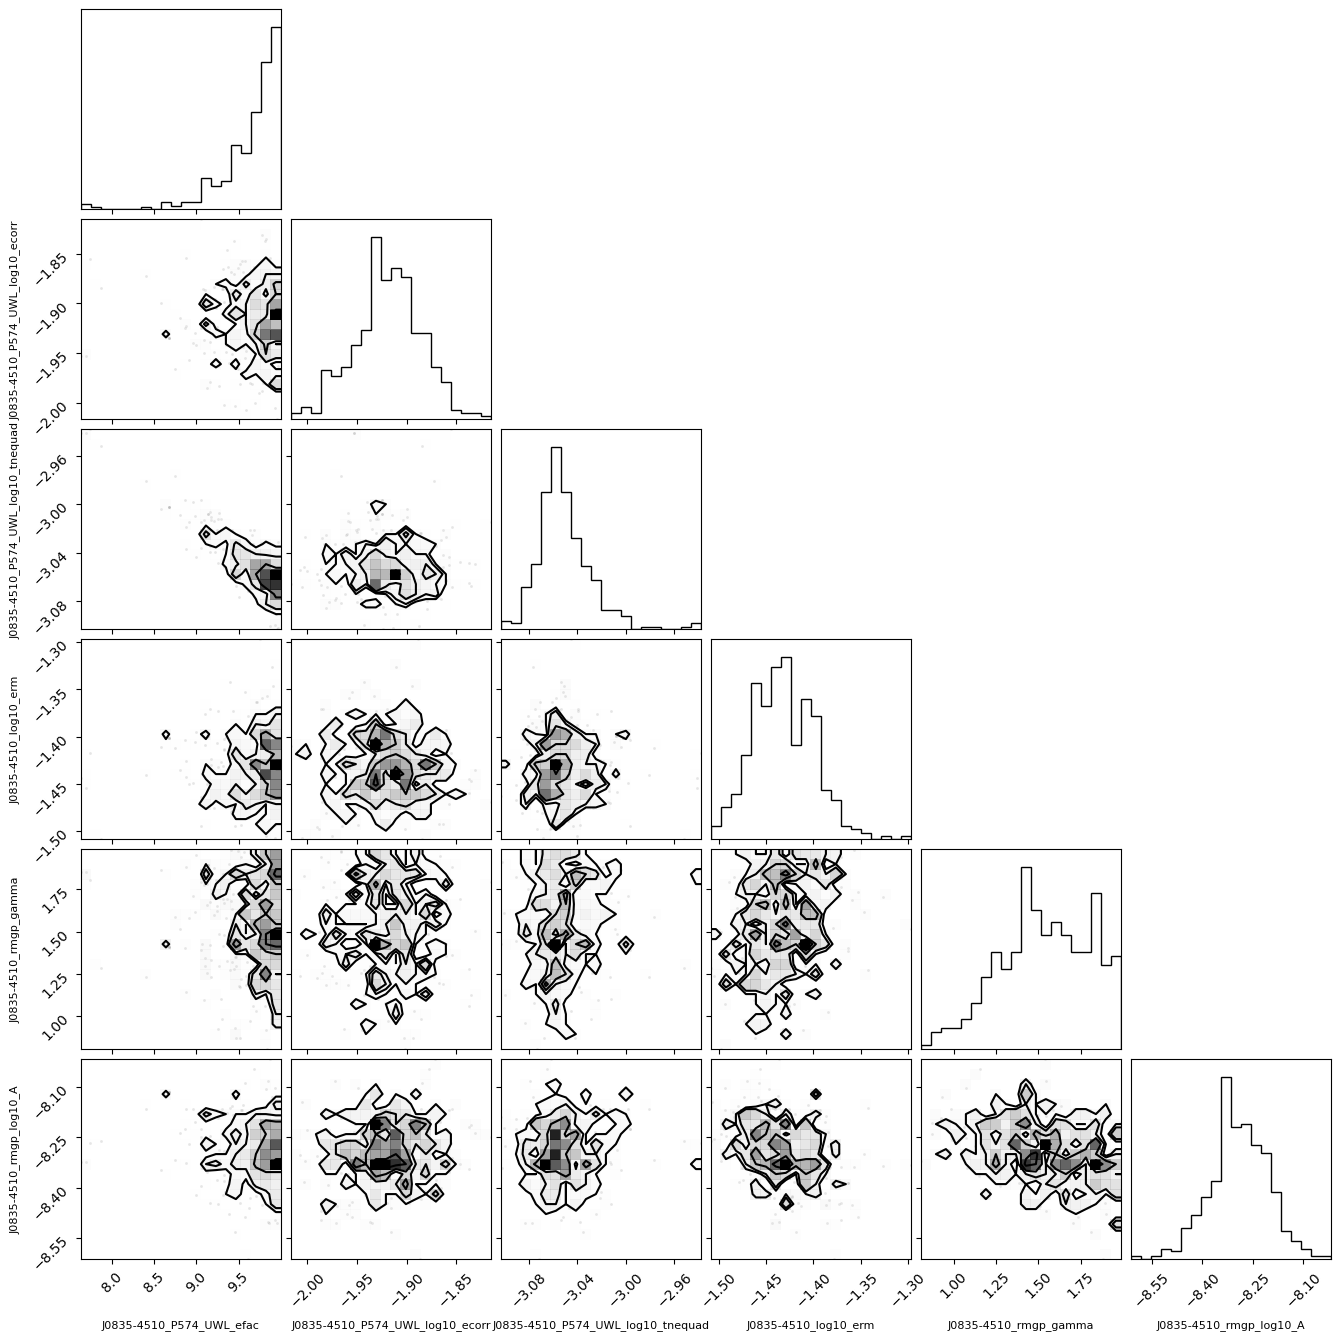

In [8]:
with np.load(f"{fitres_path}/J0835-4510_mcmc_samples_20261029-181506.npz") as loaded_results:
    raw_samples = loaded_results['raw']

    p_fit = {}
    for i, name in enumerate(logL.params):
        col = raw_samples[:, i]
        print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  range=[{min(col):.3f}, {max(col):.3f}]')
        p_fit[name] = col.mean()

    print(p_fit)
    print(f'{logL(p_fit):e}')

    figure = corner.corner(
            loaded_results['raw'],
            labels=logL.params,
            label_kwargs={"fontsize": 8}
        )
    plt.show()

[]

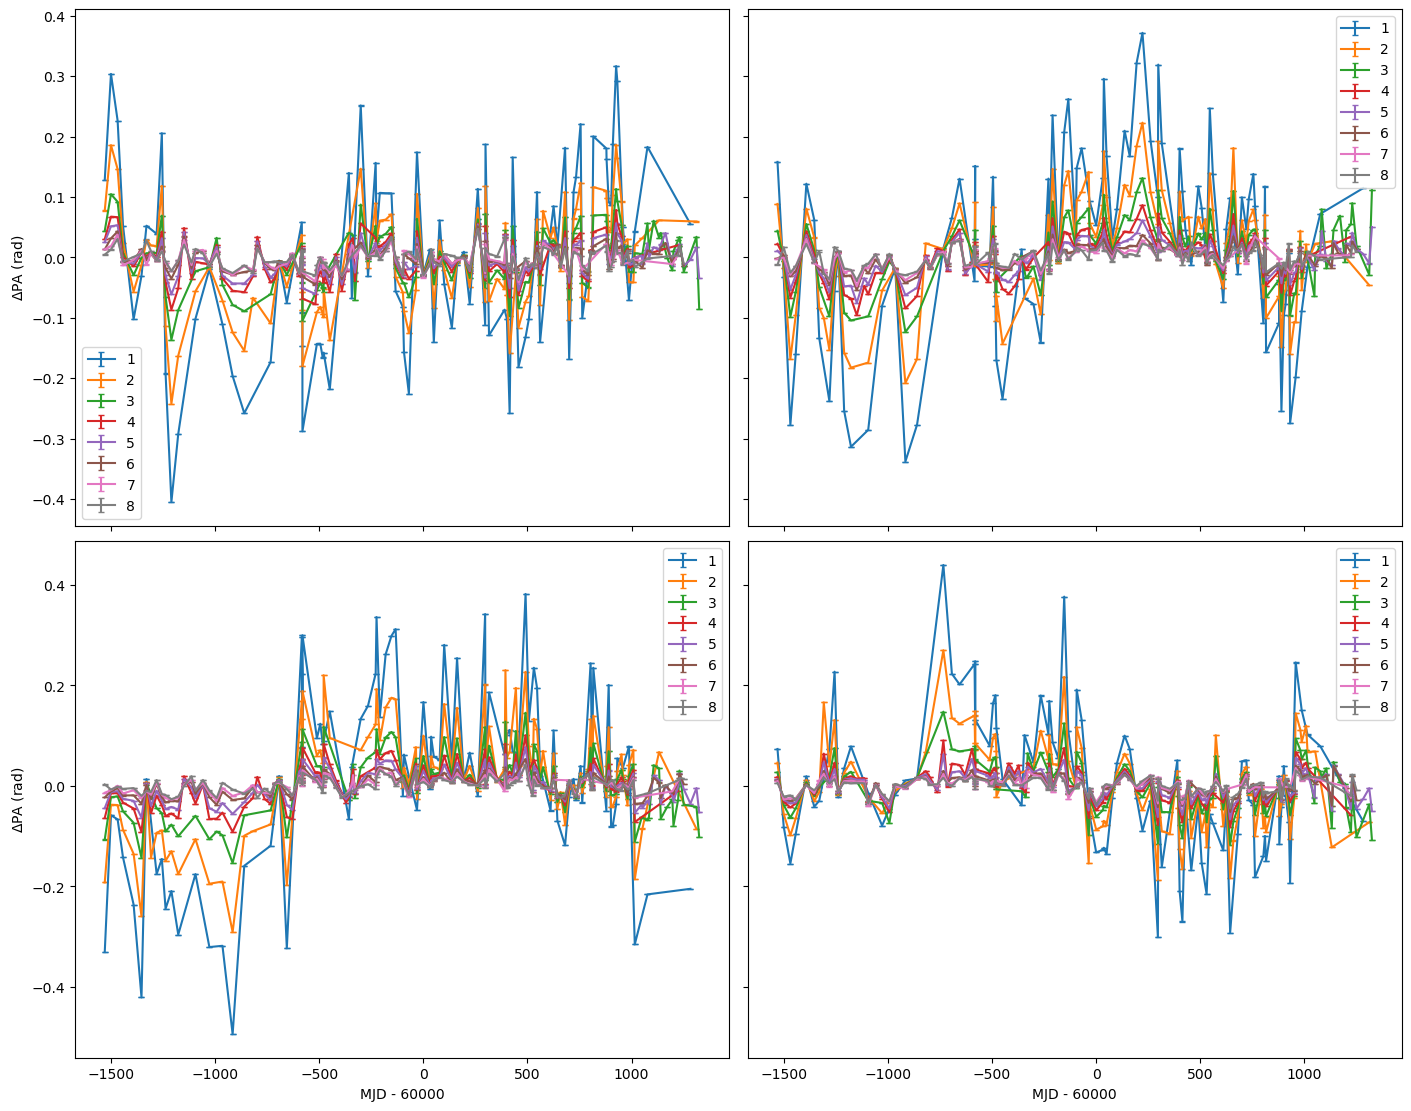

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = m_RM.sample(key, p_fit)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()

#### 2026/10/30 20:01:20

In [10]:
psr = ds.Pulsar.read_feather(f'{PA_path}/J0835-4510.PA.head_derot.minusSBmean.feather', json_metadata=False)
m_RM = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement(psr),
                         ds.makegp_ecorr(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp')
                         ])
logL = m_RM.logL

J0835-4510_P574_UWL_efac       mean=+5.135  std=2.408  range=[0.847, 9.915]
J0835-4510_P574_UWL_log10_ecorr mean=-1.621  std=0.036  range=[-1.724, -1.520]
J0835-4510_P574_UWL_log10_t2equad mean=-2.218  std=0.247  range=[-2.578, -1.511]
J0835-4510_rmgp_gamma          mean=+1.234  std=0.225  range=[0.330, 1.768]
J0835-4510_rmgp_log10_A        mean=-8.136  std=0.049  range=[-8.291, -7.979]
{'J0835-4510_P574_UWL_efac': np.float64(5.135420613133877), 'J0835-4510_P574_UWL_log10_ecorr': np.float64(-1.6208427609343976), 'J0835-4510_P574_UWL_log10_t2equad': np.float64(-2.217738518827997), 'J0835-4510_rmgp_gamma': np.float64(1.234039748152427), 'J0835-4510_rmgp_log10_A': np.float64(-8.136270278949059)}


2.603039e+03


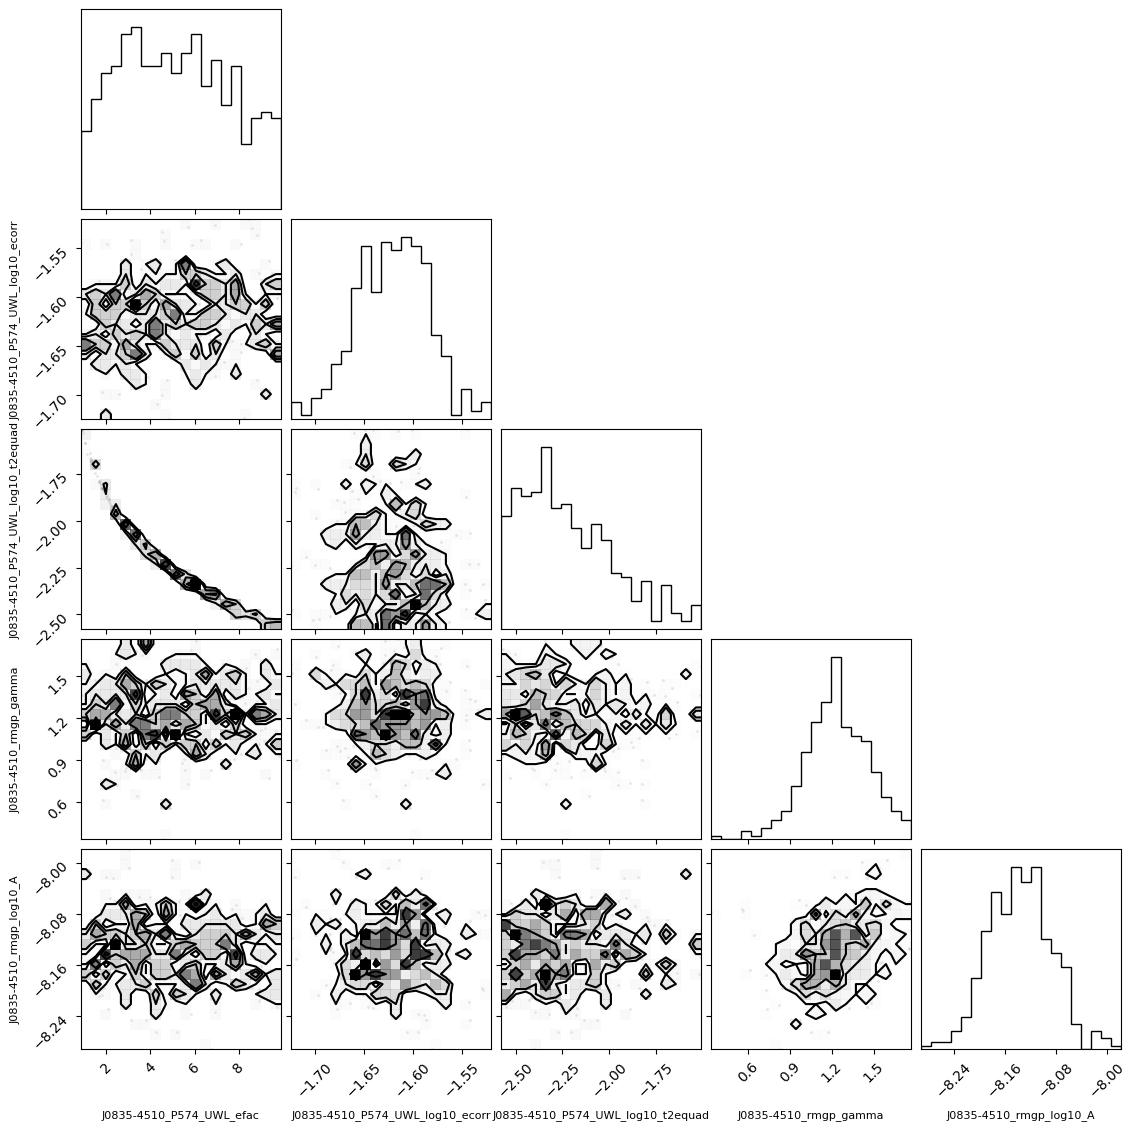

In [11]:
with np.load(f"{fitres_path}/J0835-4510_mcmc_samples_20261030-200120.npz") as loaded_results:
    raw_samples = loaded_results['raw']

    p_fit = {}
    for i, name in enumerate(logL.params):
        col = raw_samples[:, i]
        print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  range=[{min(col):.3f}, {max(col):.3f}]')
        p_fit[name] = col.mean()

    print(p_fit)
    print(f'{logL(p_fit):e}')

    figure = corner.corner(
            loaded_results['raw'],
            labels=logL.params,
            label_kwargs={"fontsize": 8}
        )
    plt.show()

[]

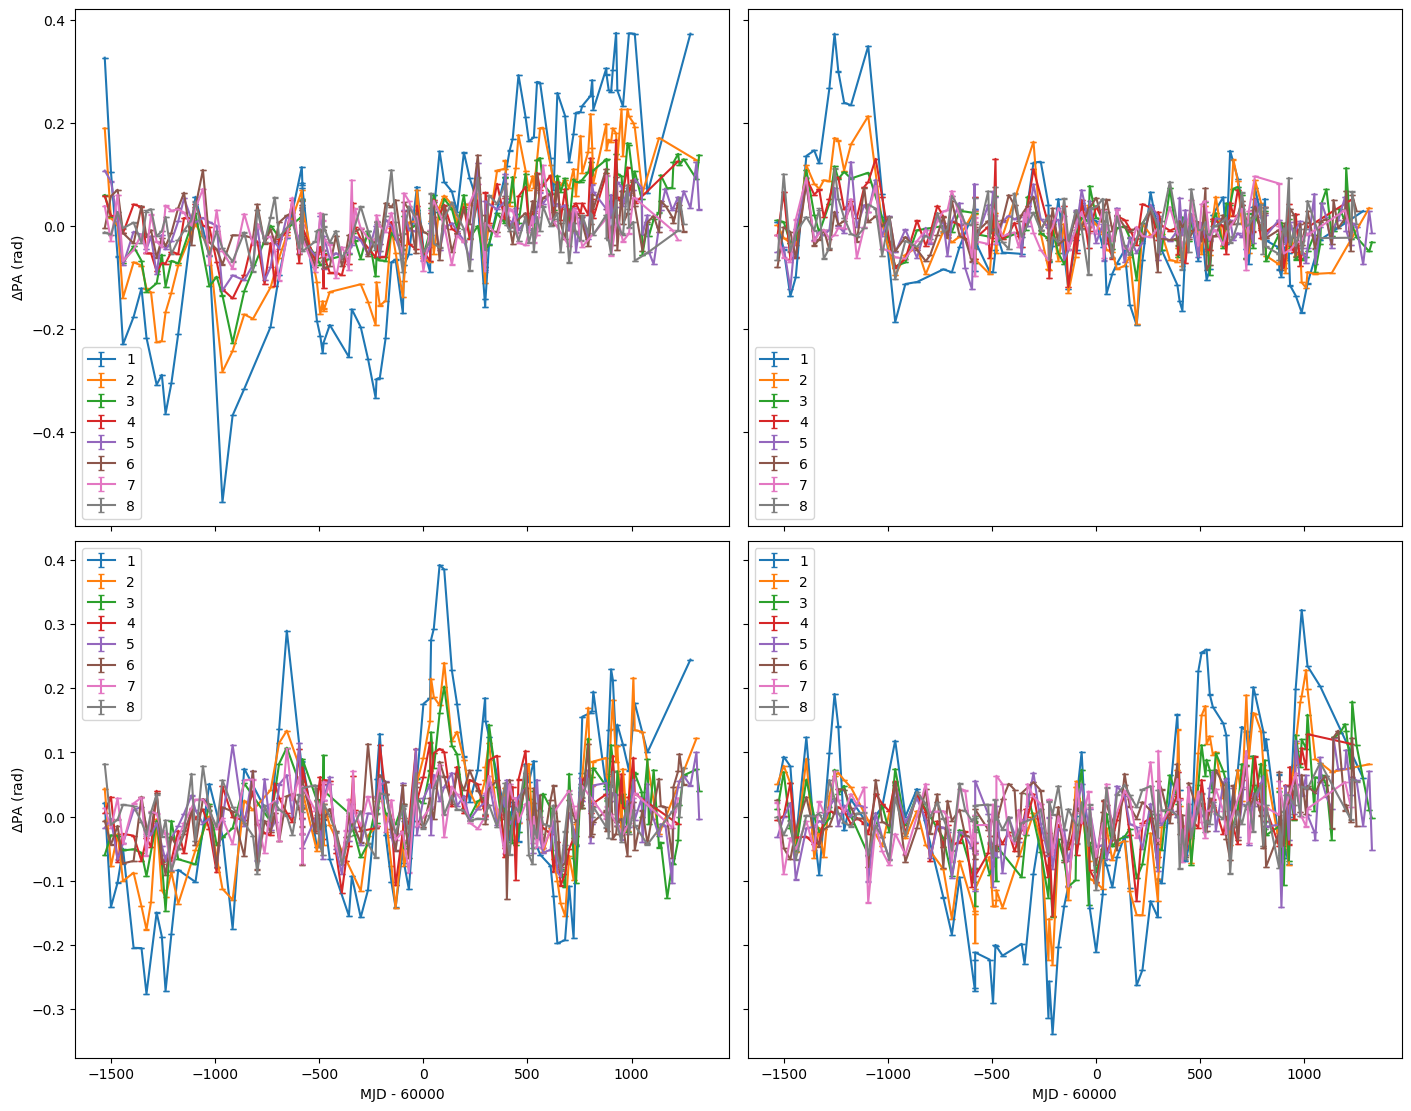

In [12]:
fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = m_RM.sample(key, p_fit)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()

#### 2026/10/31 17:12:41

In [13]:
psr = ds.Pulsar.read_feather(f'{PA_path}/J0835-4510.PA.head_derot.minusSBmean.feather', json_metadata=False)
m_RM = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement(psr, tnequad=True),
                         ds.makegp_ecorr(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp')
                         ])
logL = m_RM.logL

J0835-4510_P574_UWL_efac       mean=+4.715  std=2.738  range=[0.111, 9.971]
J0835-4510_P574_UWL_log10_ecorr mean=-1.619  std=0.035  range=[-1.726, -1.516]
J0835-4510_P574_UWL_log10_tnequad mean=-1.566  std=0.012  range=[-1.605, -1.528]
J0835-4510_rmgp_gamma          mean=+1.274  std=0.237  range=[0.460, 1.868]
J0835-4510_rmgp_log10_A        mean=-8.130  std=0.048  range=[-8.237, -7.998]
{'J0835-4510_P574_UWL_efac': np.float64(4.714722365603481), 'J0835-4510_P574_UWL_log10_ecorr': np.float64(-1.6194373961863937), 'J0835-4510_P574_UWL_log10_tnequad': np.float64(-1.5663591087027993), 'J0835-4510_rmgp_gamma': np.float64(1.2740636085909158), 'J0835-4510_rmgp_log10_A': np.float64(-8.12953460125679)}
2.615701e+03


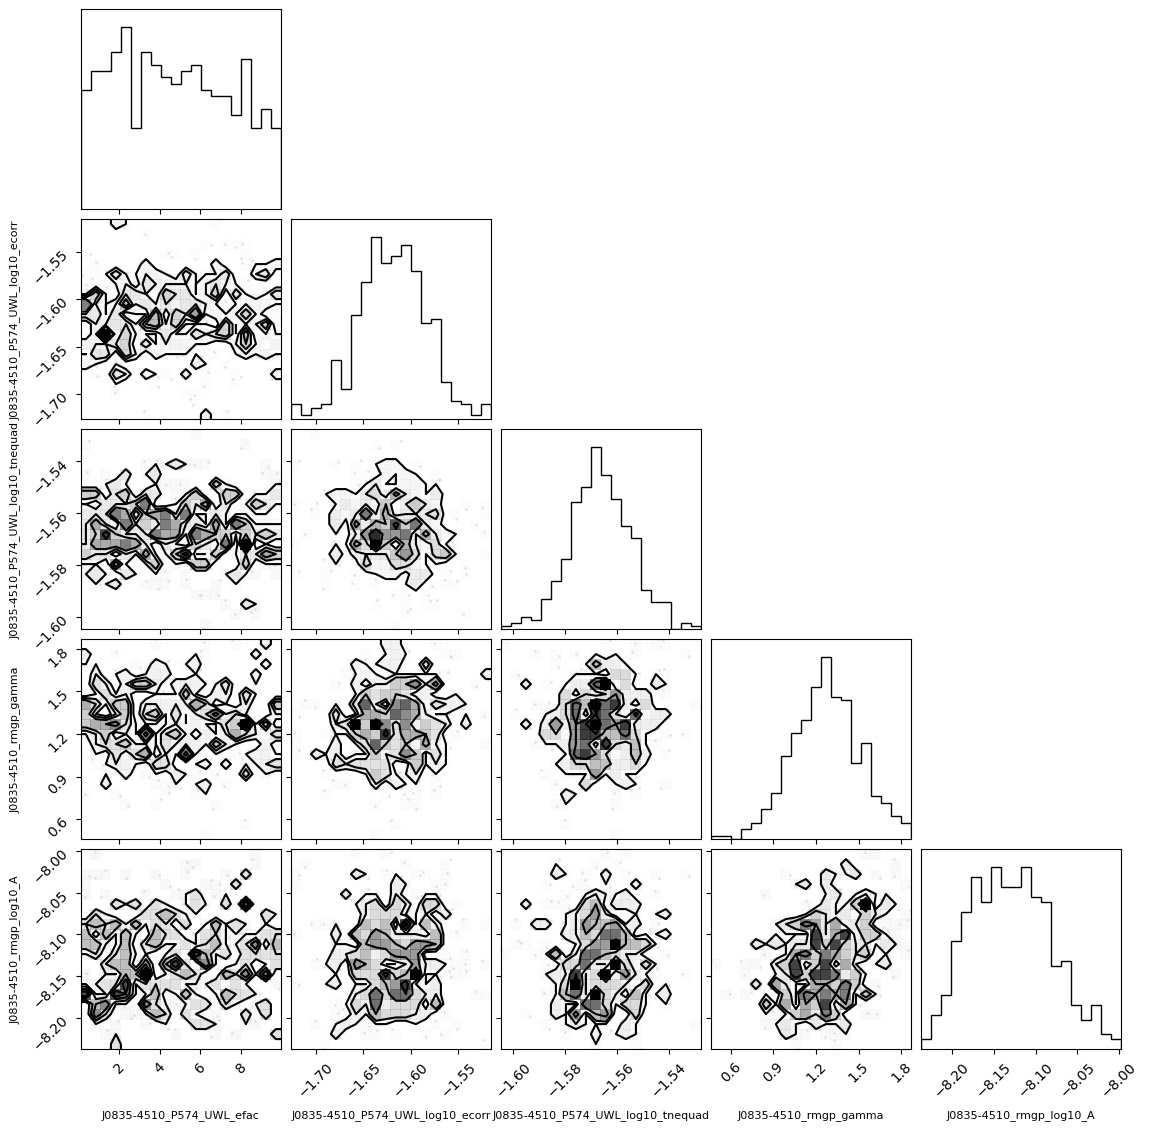

In [14]:
with np.load(f"{fitres_path}/J0835-4510_mcmc_samples_20261031-171241.npz") as loaded_results:
    raw_samples = loaded_results['raw']

    p_fit = {}
    for i, name in enumerate(logL.params):
        col = raw_samples[:, i]
        print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  range=[{min(col):.3f}, {max(col):.3f}]')
        p_fit[name] = col.mean()

    print(p_fit)
    print(f'{logL(p_fit):e}')

    figure = corner.corner(
            loaded_results['raw'],
            labels=logL.params,
            label_kwargs={"fontsize": 8}
        )
    plt.show()

[]

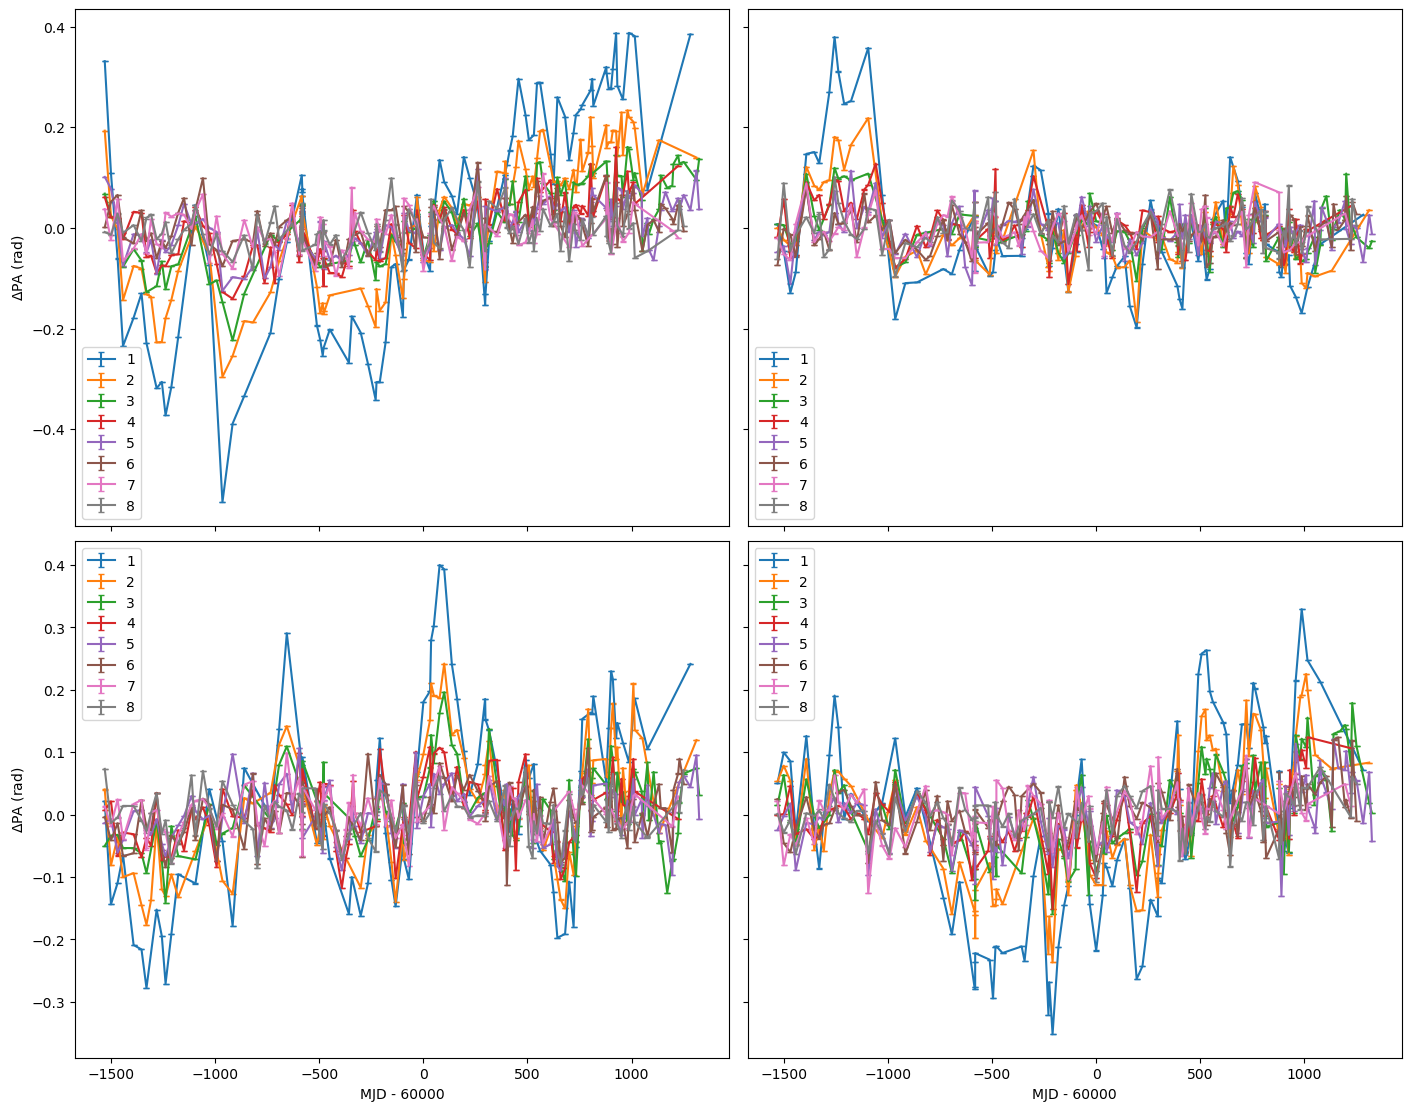

In [15]:
fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = m_RM.sample(key, p_fit)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()

#### 2026/10/31 23:43:18

J0835-4510_P574_UWL_efac_log10 mean=-0.056  std=0.546  range=[-0.986, 0.993]
J0835-4510_P574_UWL_log10_ecorr mean=-1.617  std=0.035  range=[-1.736, -1.518]
J0835-4510_P574_UWL_log10_tnequad mean=-1.567  std=0.011  range=[-1.597, -1.532]
J0835-4510_rmgp_gamma          mean=+1.266  std=0.246  range=[0.460, 1.884]
J0835-4510_rmgp_log10_A        mean=-8.132  std=0.045  range=[-8.244, -7.993]
{'J0835-4510_P574_UWL_efac_log10': np.float64(-0.05614844737755823), 'J0835-4510_P574_UWL_log10_ecorr': np.float64(-1.6168429420037547), 'J0835-4510_P574_UWL_log10_tnequad': np.float64(-1.5669319189178532), 'J0835-4510_rmgp_gamma': np.float64(1.2664781821352171), 'J0835-4510_rmgp_log10_A': np.float64(-8.132460399172608)}
2.615798e+03


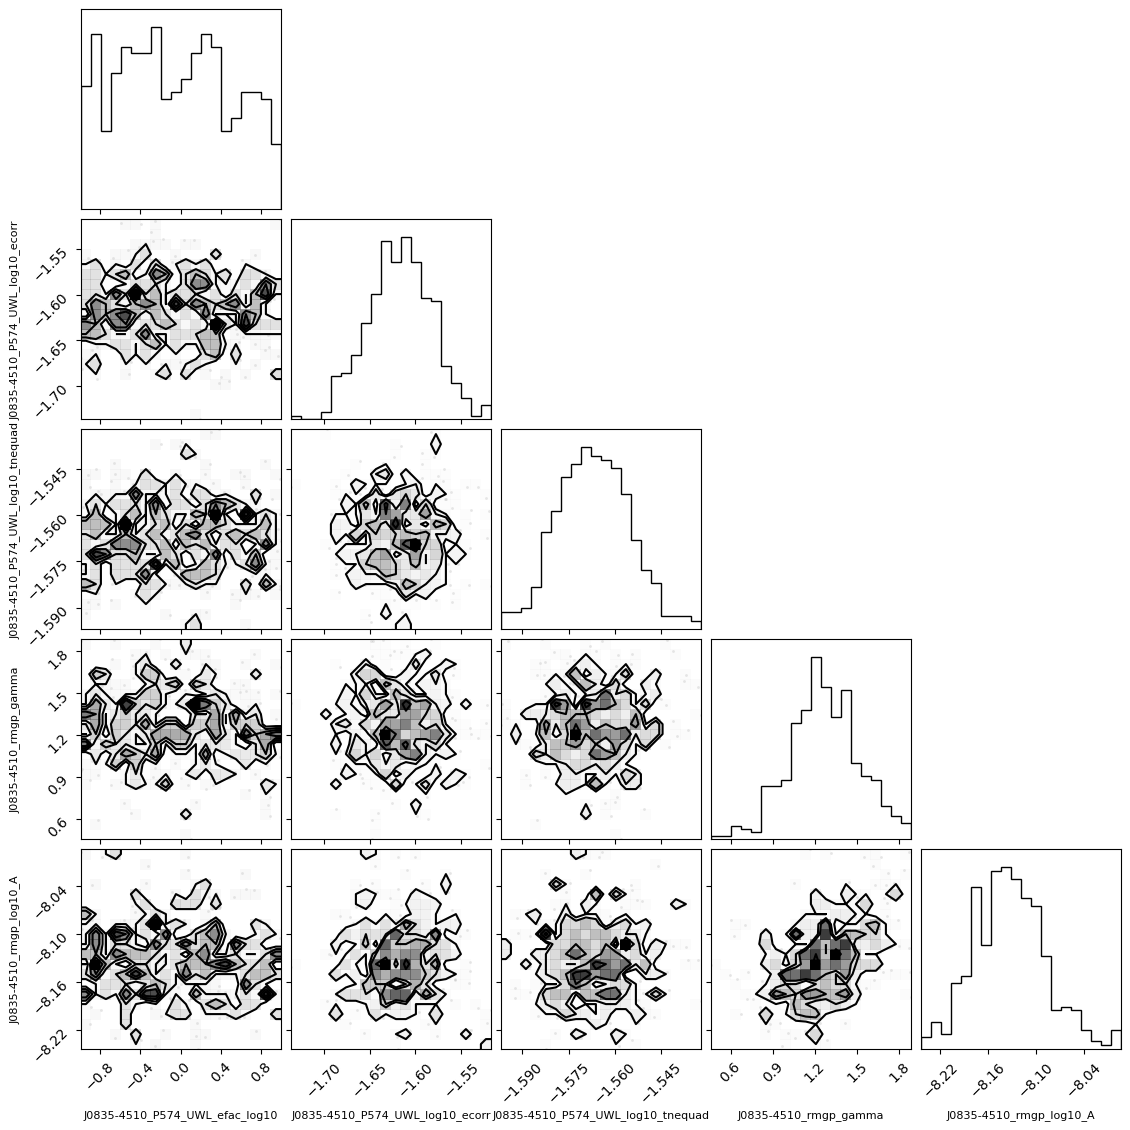

In [17]:
psr = ds.Pulsar.read_feather(f'{PA_path}/J0835-4510.PA.head_derot.minusSBmean.feather', json_metadata=False)
m_RM = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement(psr, tnequad=True, log_efac=True),
                         ds.makegp_ecorr(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp')
                         ])
logL = m_RM.logL

with np.load(f"{fitres_path}/J0835-4510_mcmc_samples_20261031-234318.npz") as loaded_results:
    raw_samples = loaded_results['raw']

    p_fit = {}
    for i, name in enumerate(logL.params):
        col = raw_samples[:, i]
        print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  range=[{min(col):.3f}, {max(col):.3f}]')
        p_fit[name] = col.mean()

    print(p_fit)
    print(f'{logL(p_fit):e}')

    figure = corner.corner(
            loaded_results['raw'],
            labels=logL.params,
            label_kwargs={"fontsize": 8}
        )
    plt.show()

[]

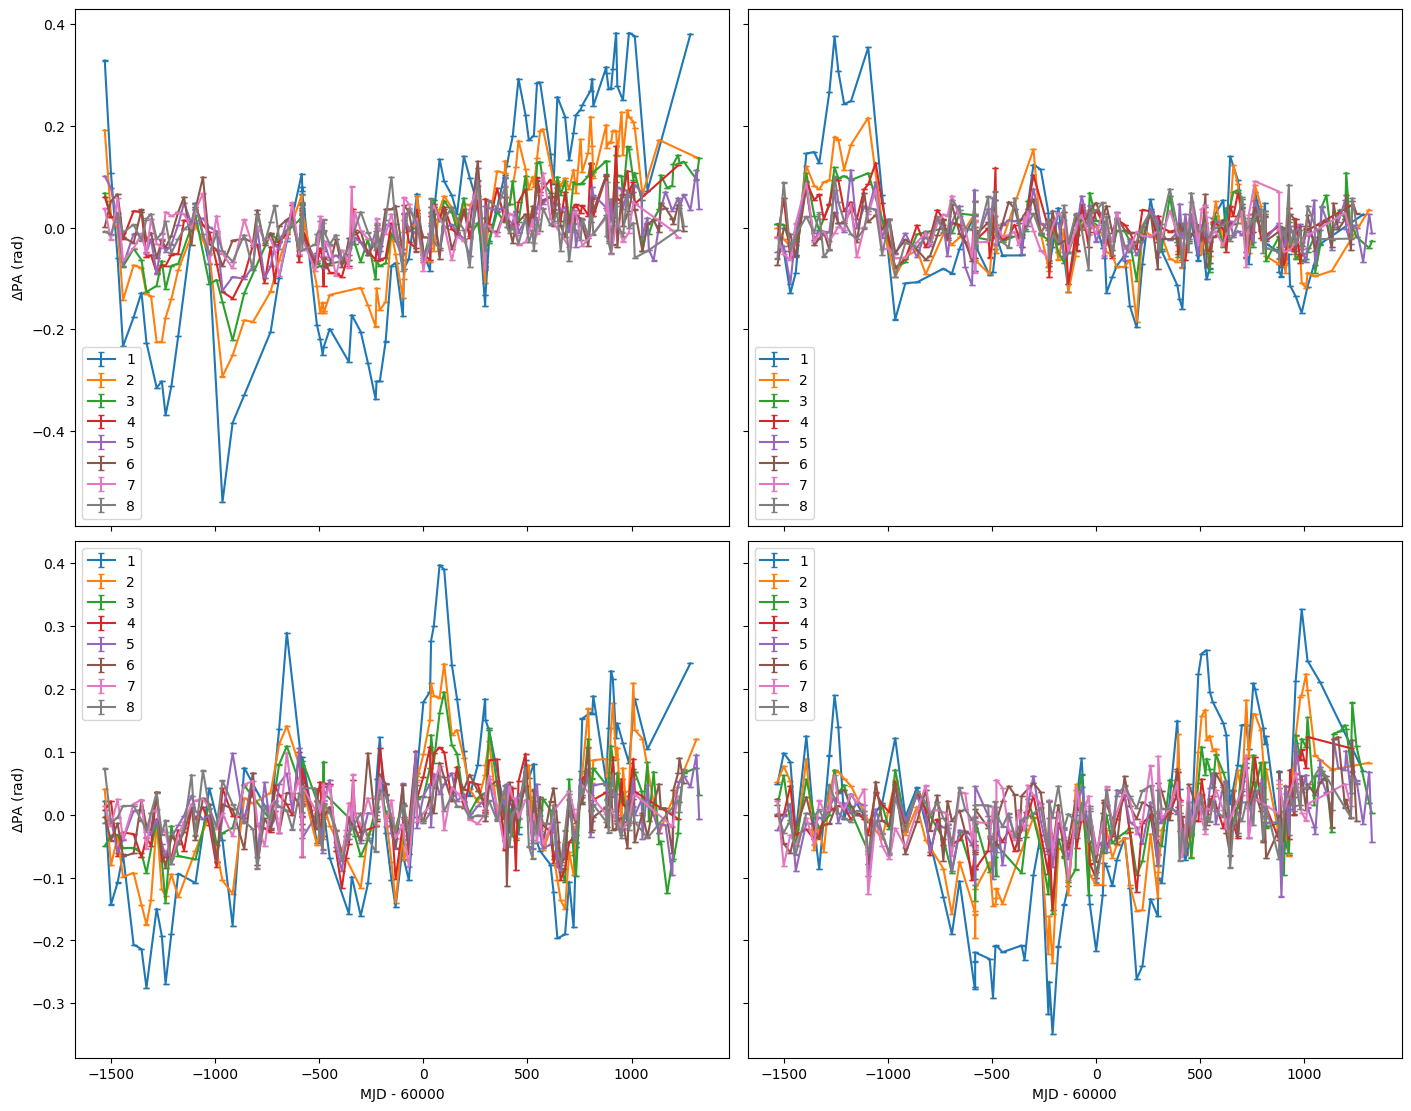

In [18]:
fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = m_RM.sample(key, p_fit)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()

#### 2026/10/31 23:59:35

J0835-4510_P574_UWL_efac_log10 mean=+0.983  std=0.019  range=[0.884, 1.000]
J0835-4510_P574_UWL_log10_ecorr mean=-1.918  std=0.036  range=[-2.013, -1.801]
J0835-4510_P574_UWL_log10_tnequad mean=-2.068  std=0.014  range=[-2.118, -2.034]
J0835-4510_log10_erm           mean=-1.437  std=0.032  range=[-1.537, -1.349]
J0835-4510_rmgp_gamma          mean=+1.559  std=0.254  range=[0.938, 1.998]
J0835-4510_rmgp_log10_A        mean=-8.288  std=0.093  range=[-8.567, -8.058]
{'J0835-4510_P574_UWL_efac_log10': np.float64(0.982596195648743), 'J0835-4510_P574_UWL_log10_ecorr': np.float64(-1.9180397388200772), 'J0835-4510_P574_UWL_log10_tnequad': np.float64(-2.0679435126260057), 'J0835-4510_log10_erm': np.float64(-1.436593880888439), 'J0835-4510_rmgp_gamma': np.float64(1.5590740690472602), 'J0835-4510_rmgp_log10_A': np.float64(-8.287573236768155)}
3.362635e+03


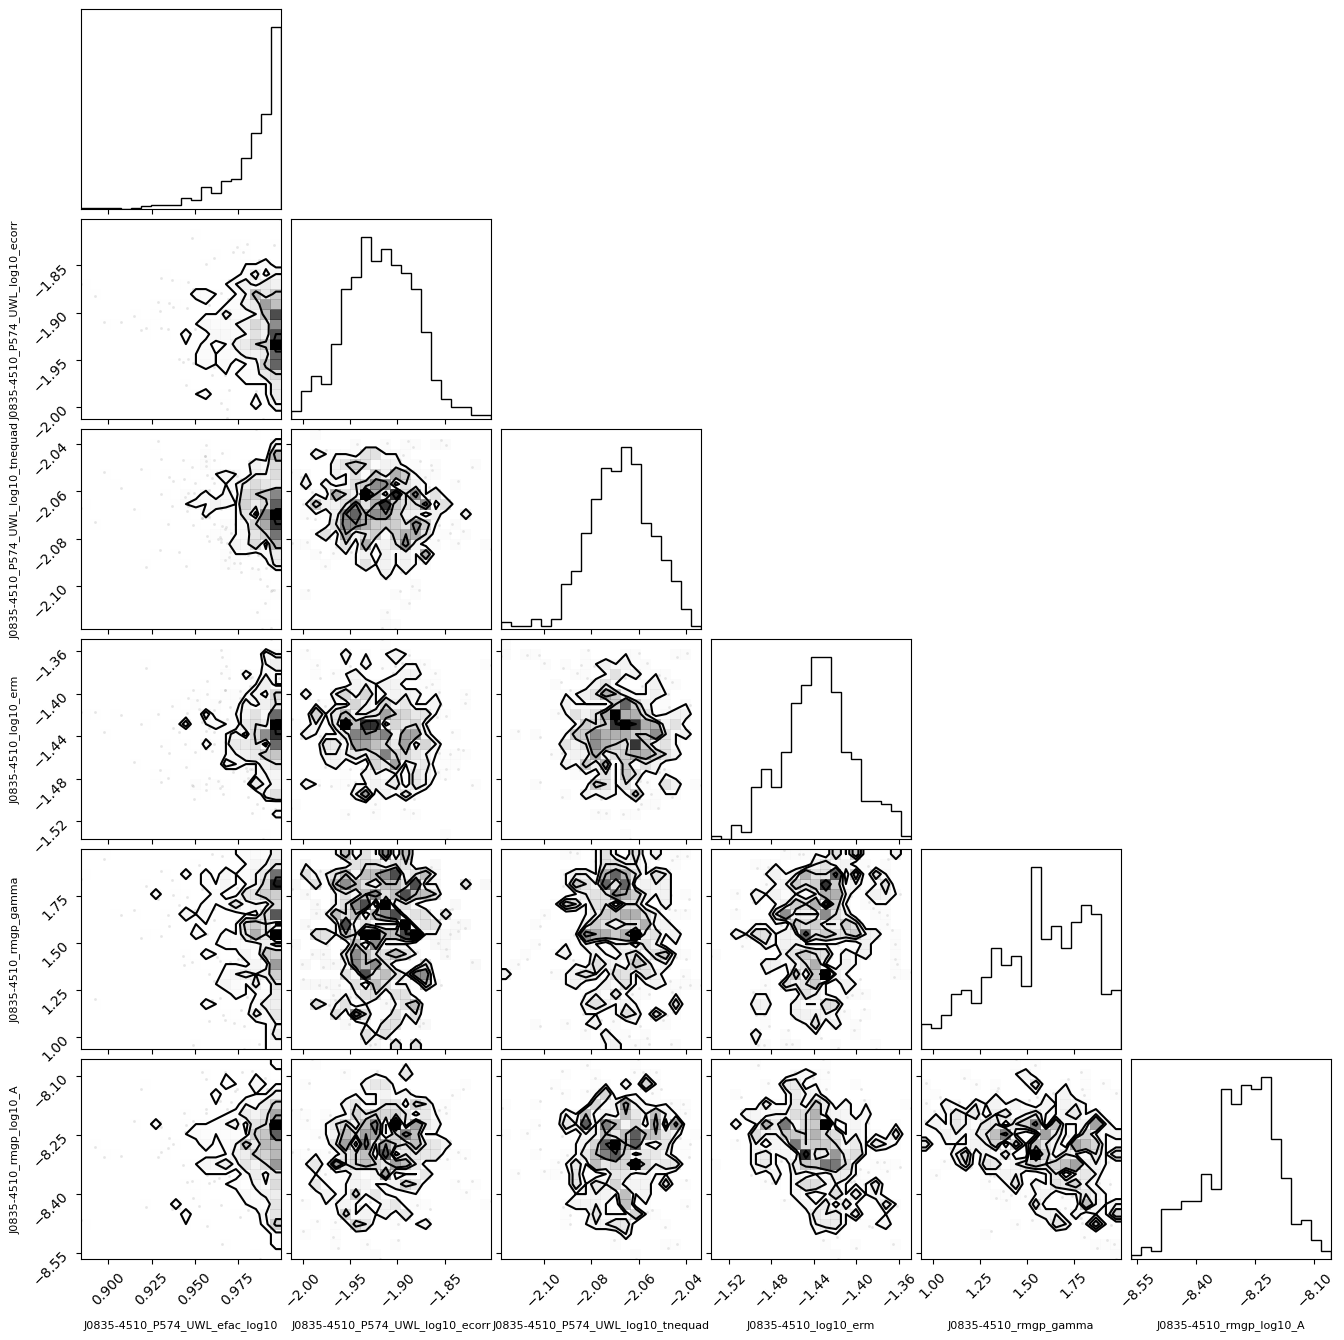

In [20]:
psr = ds.Pulsar.read_feather(f'{PA_path}/J0835-4510.PA.head_derot.minusSBmean.feather', json_metadata=False)
m_RM = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement(psr, tnequad=True, log_efac=True),
                         ds.makegp_ecorr(psr),
                         ds.makegp_erm(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp')
                         ])
logL = m_RM.logL

with np.load(f"{fitres_path}/J0835-4510_mcmc_samples_20261031-235935.npz") as loaded_results:
    raw_samples = loaded_results['raw']

    p_fit = {}
    for i, name in enumerate(logL.params):
        col = raw_samples[:, i]
        print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  range=[{min(col):.3f}, {max(col):.3f}]')
        p_fit[name] = col.mean()

    print(p_fit)
    print(f'{logL(p_fit):e}')

    figure = corner.corner(
            loaded_results['raw'],
            labels=logL.params,
            label_kwargs={"fontsize": 8}
        )
    plt.show()

[]

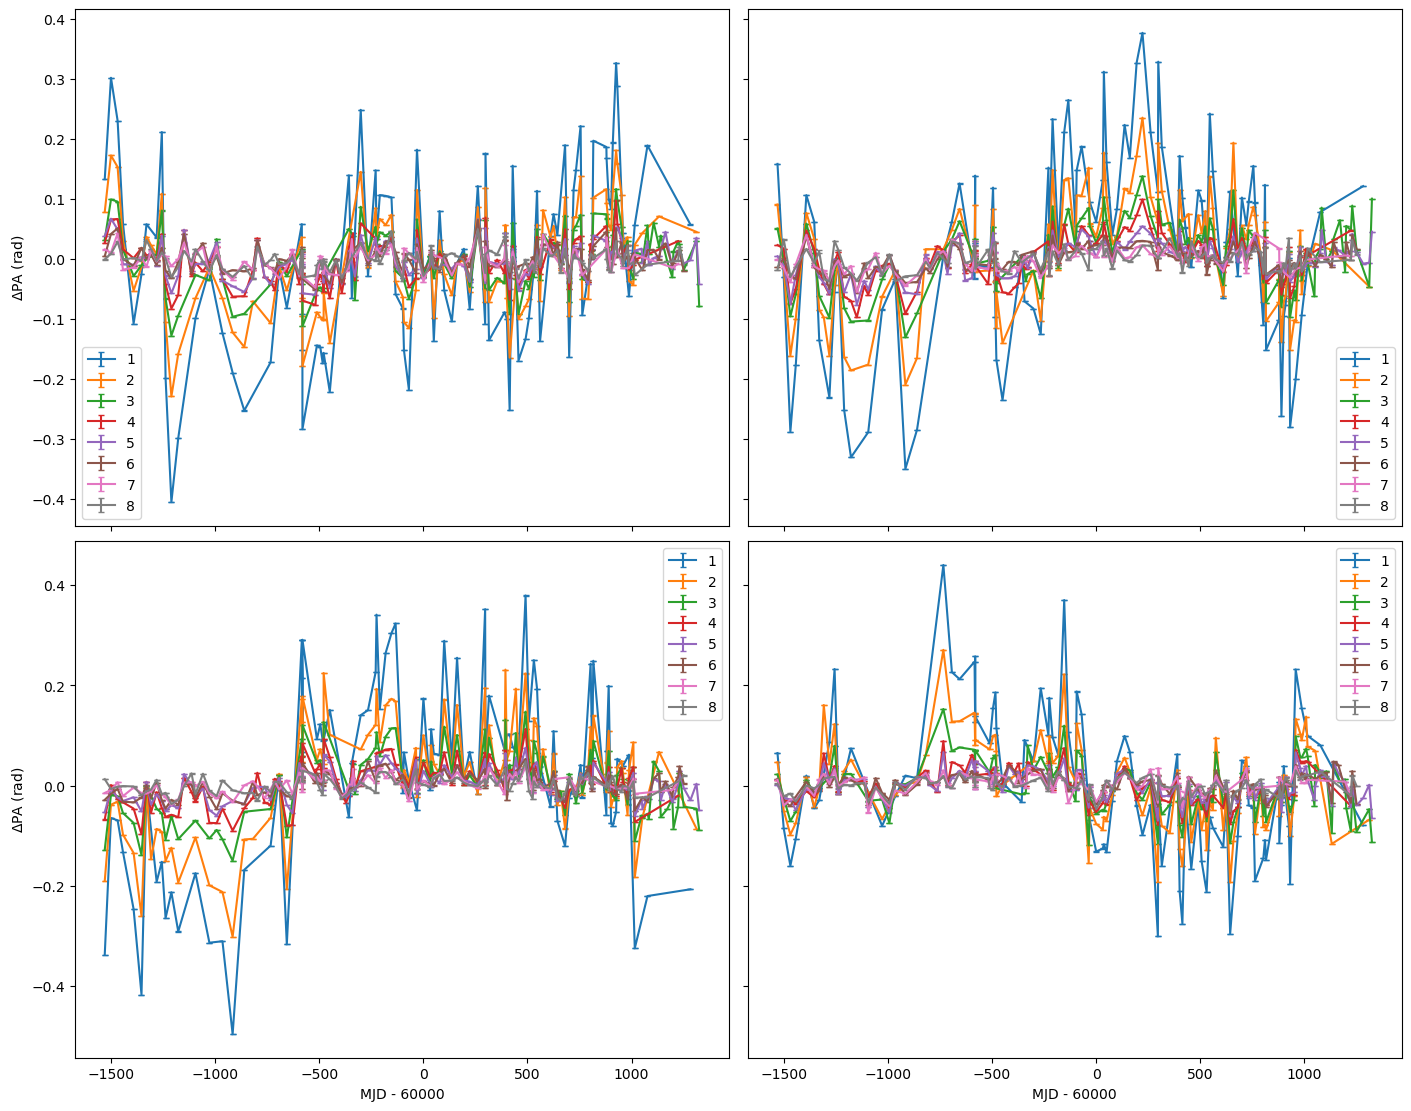

In [21]:
fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = m_RM.sample(key, p_fit)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()